In [21]:
import pandas as pd

# 读取 CSV 文件
file_path = 'data_12k_1797_10c.csv'
data = pd.read_csv(file_path)

# 1. 查看数据的基本信息
print("数据基本信息：")
data.info()

# 2. 查看数据集行数和列数
rows, columns = data.shape

if rows < 1000:
    # 小样本集全量计算描述性统计指标
    print("数据全部内容信息：")
    print(data.to_csv(sep='\t', na_rep='nan'))
else:
    # 大样本集截取头部样本展示结构特征
    print("数据前几行内容信息：")
    print(data.head().to_csv(sep='\t', na_rep='nan'))

# 3. 查看数据集行数和列数
rows, columns = data.shape

if columns < 10:
    # 特征数量少于10时查看全量特征的描述性统计信息
    print("数据全部内容的描述性统计信息：")
    print(data.describe().to_csv(sep='\t', na_rep='nan'))
else:
    # 特征数量多于10时查看数据前几行特征的描述性统计信息
    print("数据前几行内容的描述性统计信息：")
    print(data.head().describe().to_csv(sep='\t', na_rep='nan'))

# 4. 查看数据的缺失值情况
missing_values = data.isnull().sum()
print("数据的缺失值情况：")
print(missing_values)

# 5. 分析数据集目标类别与离散特征的分布特征
if 'object' in data.dtypes.tolist():
    categorical_columns = data.select_dtypes(include=['object']).columns
    for col in categorical_columns:
        print(f"\n类别特征 {col} 的分布情况：")
        print(data[col].value_counts())

数据基本信息：
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119808 entries, 0 to 119807
Data columns (total 10 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   de_normal    119808 non-null  float64
 1   de_7_inner   119808 non-null  float64
 2   de_7_ball    119808 non-null  float64
 3   de_7_outer   119808 non-null  float64
 4   de_14_inner  119808 non-null  float64
 5   de_14_ball   119808 non-null  float64
 6   de_14_outer  119808 non-null  float64
 7   de_21_inner  119808 non-null  float64
 8   de_21_ball   119808 non-null  float64
 9   de_21_outer  119808 non-null  float64
dtypes: float64(10)
memory usage: 9.1 MB
数据前几行内容信息：
	de_normal	de_7_inner	de_7_ball	de_7_outer	de_14_inner	de_14_ball	de_14_outer	de_21_inner	de_21_ball	de_21_outer
0	0.053196923	-0.083004351	-0.002761397	0.008527844	-0.223835609	-0.467813174	0.002273533	1.189431238	-0.007959321	0.104364571
1	0.088661538	-0.195734331	-0.096324032	0.423549601	-0.209541317	0.179003

In [22]:
data.shape # 检查数据集空间维度 (样本数, 特征数)

(119808, 10)

In [23]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119808 entries, 0 to 119807
Data columns (total 10 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   de_normal    119808 non-null  float64
 1   de_7_inner   119808 non-null  float64
 2   de_7_ball    119808 non-null  float64
 3   de_7_outer   119808 non-null  float64
 4   de_14_inner  119808 non-null  float64
 5   de_14_ball   119808 non-null  float64
 6   de_14_outer  119808 non-null  float64
 7   de_21_inner  119808 non-null  float64
 8   de_21_ball   119808 non-null  float64
 9   de_21_outer  119808 non-null  float64
dtypes: float64(10)
memory usage: 9.1 MB


de_normal	驱动端正常数据	驱动端轴承处于正常状态下的相关数据，可作为正常工况的参考基准，用于与故障数据对比分析
de_7_inner	驱动端轴承故障直径为 0.007 英寸的内圈数据	反映驱动端轴承内圈在故障直径为 0.007 英寸时的运行状态数据，可用于研究该故障程度下内圈的特征变化
de_7_ball	驱动端轴承故障直径为 0.007 英寸的滚动体数据	记录驱动端轴承滚动体在故障直径为 0.007 英寸时的相关数据，有助于分析此故障程度下滚动体的特性
de_7_outer	驱动端轴承故障直径为 0.007 英寸的外圈数据	呈现驱动端轴承外圈在故障直径为 0.007 英寸时的数据情况，可用于探究该故障程度下外圈的表现
de_14_inner	驱动端轴承故障直径为 0.014 英寸的内圈数据	体现驱动端轴承内圈在故障直径为 0.014 英寸时的运行参数，可对比不同故障直径下内圈数据的差异
de_14_ball	驱动端轴承故障直径为 0.014 英寸的滚动体数据	展示驱动端轴承滚动体在故障直径为 0.014 英寸时的具体数据，用于分析该故障程度下滚动体的变化
de_14_outer	驱动端轴承故障直径为 0.014 英寸的外圈数据	给出驱动端轴承外圈在故障直径为 0.014 英寸时的信息，可辅助研究此故障程度下外圈的特征
de_21_inner	驱动端轴承故障直径为 0.028 英寸的内圈数据	表示驱动端轴承内圈在故障直径为 0.028 英寸时的相关数据，用于对比不同故障程度下内圈的状态
de_21_ball	驱动端轴承故障直径为 0.028 英寸的滚动体数据	记录驱动端轴承滚动体在故障直径为 0.028 英寸时的情况，可分析该严重程度下滚动体的特性变化
de_21_outer	驱动端轴承故障直径为 0.028 英寸的外圈数据	呈现驱动端轴承外圈在故障直径为 0.028 英寸时的数据，有助于研究较严重故障下外圈的特征

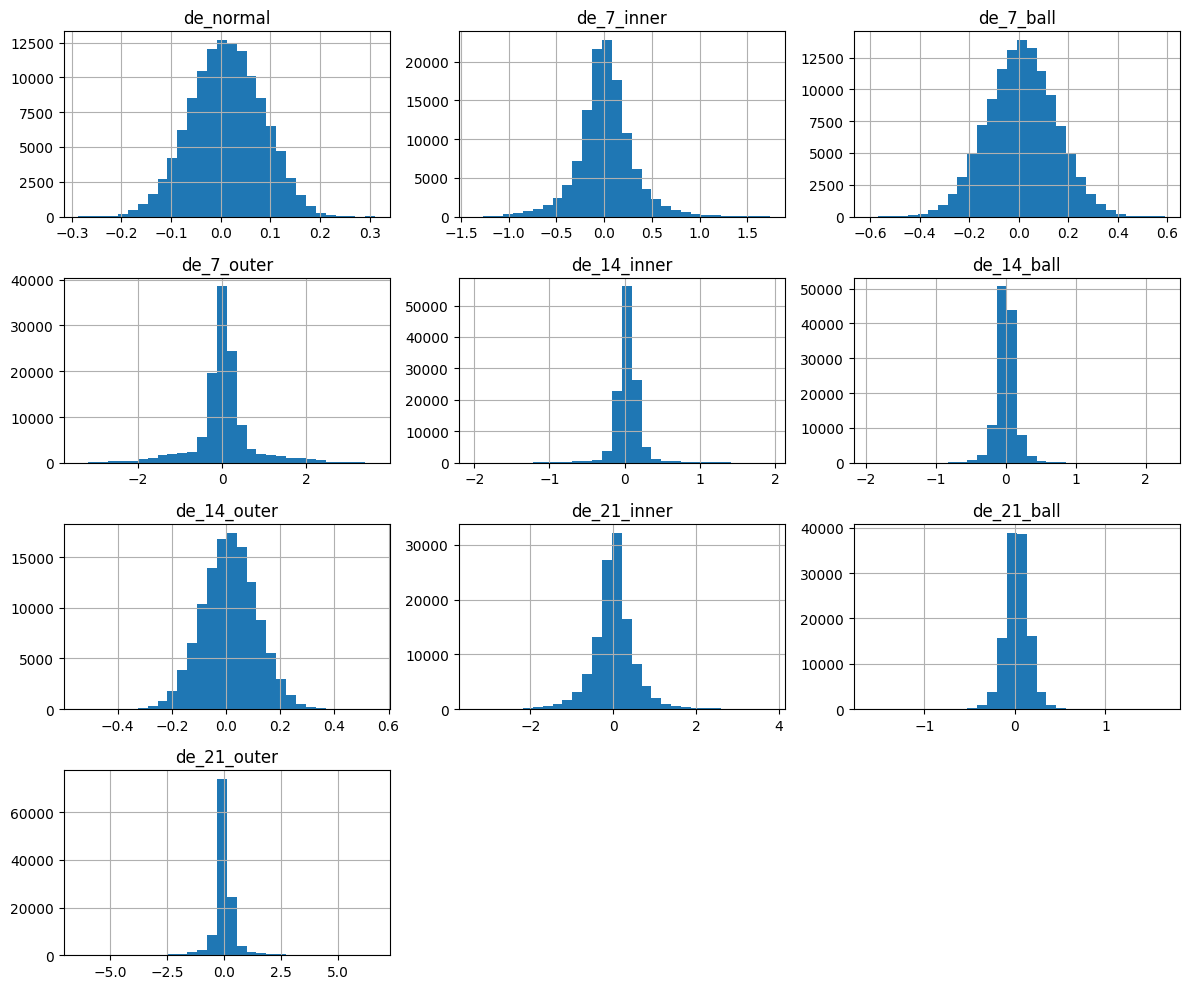

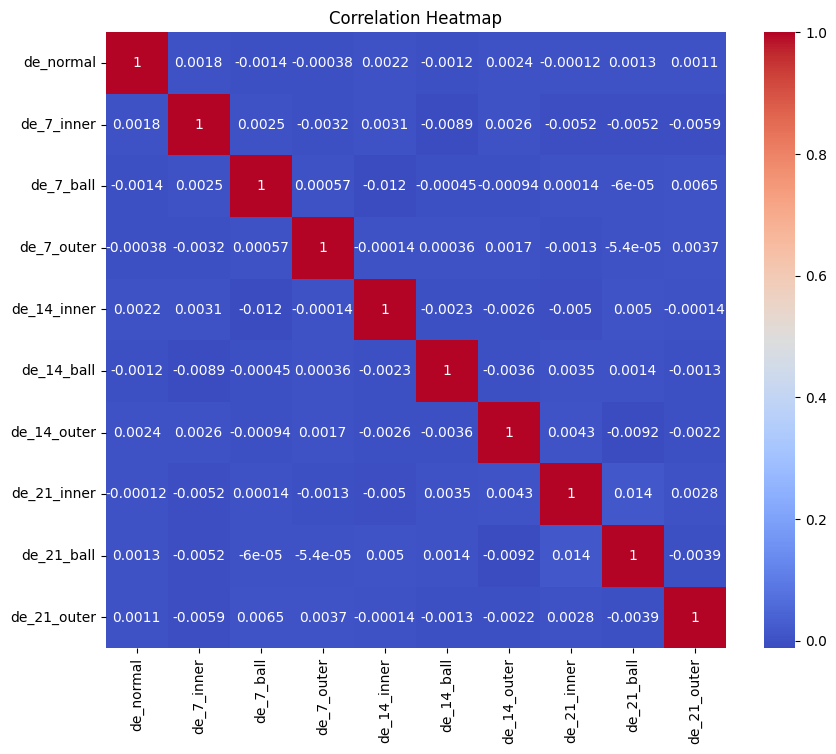

In [24]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 读取数据
df = pd.read_csv('data_12k_1797_10c.csv')

# 绘制各列的直方图
df.hist(figsize=(12, 10), bins=30)
plt.tight_layout()
plt.show()

# 计算相关性矩阵
correlation_matrix = df.corr()

# 绘制相关性热力图
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

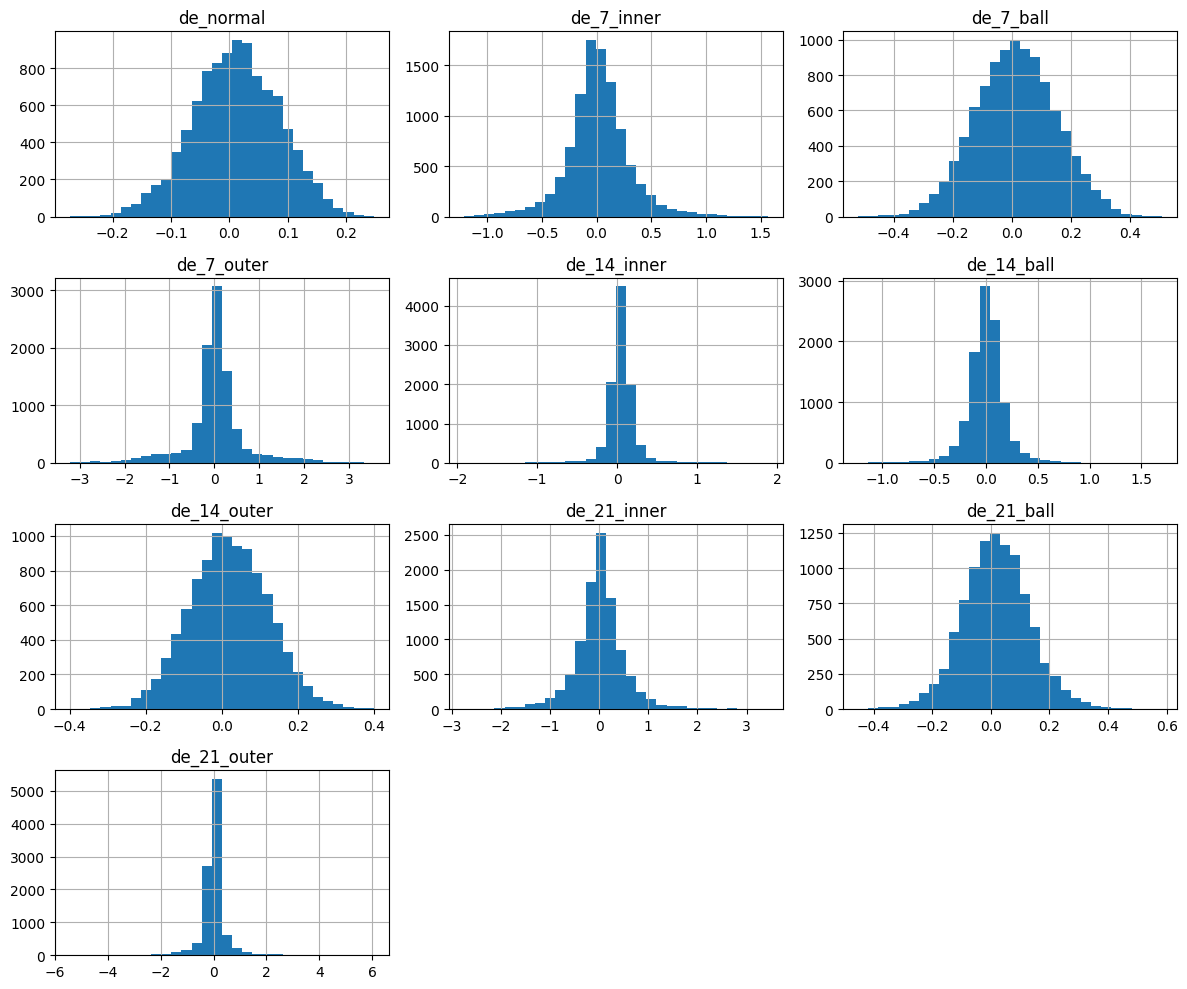

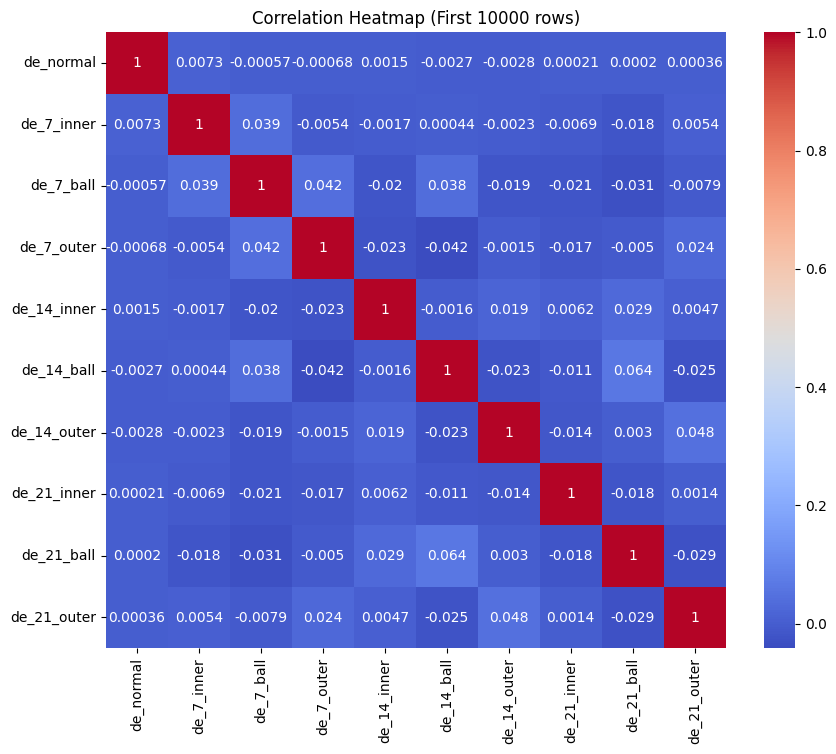

In [25]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 读取数据
file_path = 'data_12k_1797_10c.csv'
data = pd.read_csv(file_path)

# 取前 10000 行数据
subset_data = data.head(10000)

# 绘制各列的直方图
subset_data.hist(figsize=(12, 10), bins=30)
plt.tight_layout()
plt.show()

# 计算相关性矩阵
correlation_matrix = subset_data.corr()

# 绘制相关性热力图
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap (First 10000 rows)')
plt.show()

特征标准化
由于各列数据的取值范围和分布不同，为了避免某些特征对模型的影响过大，需要对数据进行标准化处理。常见的方法有 StandardScaler（将数据转换为均值为 0，标准差为 1 的分布）和 MinMaxScaler（将数据缩放到 [0, 1] 区间）。

In [35]:
import pandas as pd

# 读取数据
file_path = 'data_12k_1797_10c.csv'
data = pd.read_csv(file_path).head(10000)

# 定义函数来构建标签
def create_label(row):
    # 如果 de_normal 列有值（表示正常），标签为 0
    if row['de_normal'] > 0:  # 依据基准工况设定状态标签（de_normal > 0 为正常基准状态）
        return 0
    else:
        return 1

# 应用函数到每一行数据，创建标签列
data['label'] = data.apply(create_label, axis=1)

# 查看标签分布
label_distribution = data['label'].value_counts()
print("标签分布情况：")
print(label_distribution)

标签分布情况：
label
0    5635
1    4365
Name: count, dtype: int64


In [38]:
from imblearn.over_sampling import SMOTE
import pandas as pd
from sklearn.model_selection import train_test_split

# 特征矩阵与状态标签变量分离
# 分离特征数据和标签数据
X = data.drop('label', axis = 1)
y = data['label']

# 划分训练集和测试集
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)

# 统计训练集中各类别的样本数量
class_distribution = pd.Series(y_train).value_counts()
majority_count = class_distribution.max()  # 获取多数类样本数量

# 创建 SMOTE 过采样器，设置采样策略为将少数类样本数量增加到多数类样本数量
smote = SMOTE(sampling_strategy = {1: majority_count}, random_state = 42)

# 对训练集进行过采样
X_train_resampled, y_train_resampled = smote.fit_resample(X_train, y_train)

# 查看过采样后的标签分布
resampled_label_distribution = pd.Series(y_train_resampled).value_counts()
print("过采样后的训练集标签分布：")
print(resampled_label_distribution)

过采样后的训练集标签分布：
label
1    4507
0    4507
Name: count, dtype: int64


In [45]:
import pandas as pd
from imblearn.over_sampling import SMOTE
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier
import xgboost as xgb
import lightgbm as lgb
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.model_selection import train_test_split
import pandas as pd

# 设置最大行数和列数
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None) 
# 完成训练集重采样处理

# 定义模型评估函数，用于评估模型在测试集上的性能
def evaluate_model(model, X_test, y_test):
    # 对测试集进行预测，得到预测标签
    y_pred = model.predict(X_test)
    # 根据模型是否支持 predict_proba 方法来获取预测概率或决策函数值
    if hasattr(model, 'predict_proba'):
        # 如果支持 predict_proba 方法，获取正类的预测概率
        y_pred_proba = model.predict_proba(X_test)[:, 1]
    else:
        # 如果不支持 predict_proba 方法，使用决策函数值
        y_pred_proba = model.decision_function(X_test)
    # 计算准确率
    accuracy = accuracy_score(y_test, y_pred)
    # 计算精确率
    precision = precision_score(y_test, y_pred)
    # 计算召回率
    recall = recall_score(y_test, y_pred)
    # 计算 F1 值
    f1 = f1_score(y_test, y_pred)
    # 计算测试集的 AUC 值
    test_auc = roc_auc_score(y_test, y_pred_proba)
    print(f"测试集准确率: {accuracy}")
    print(f"测试集精确率: {precision}")
    print(f"测试集召回率: {recall}")
    print(f"测试集 F1 值: {f1}")
    print(f"测试集 AUC 值: {test_auc}")
    print("-" * 30)

# 1. 逻辑回归模型
lr_model = LogisticRegression()
lr_model.fit(X_train_resampled, y_train_resampled)
print("逻辑回归模型评估结果：")
evaluate_model(lr_model, X_test, y_test)
print("逻辑回归模型权重：")
print(lr_model.coef_)



逻辑回归模型评估结果：
测试集准确率: 0.9915
测试集精确率: 0.9819616685456595
测试集召回率: 0.9988532110091743
测试集 F1 值: 0.9903354178510516
测试集 AUC 值: 0.9999085008783916
------------------------------
逻辑回归模型权重：
[[-3.89264684e+01 -1.99434220e-02 -2.20033587e-02  4.18167841e-02
   5.92993704e-04  1.48822044e-01  1.60090711e-01 -4.14262822e-02
  -8.68315688e-03  2.51043114e-02]]


In [46]:
# 2. SVM 模型
svm_model = SVC(probability=True)  # 需要设置 probability=True 才能使用 predict_proba
svm_model.fit(X_train_resampled, y_train_resampled)
print("SVM 模型评估结果：")
evaluate_model(svm_model, X_test, y_test)
print("SVM 模型支持向量系数：")
print(svm_model.dual_coef_)



SVM 模型评估结果：
测试集准确率: 0.946
测试集精确率: 0.9282511210762332
测试集召回率: 0.9495412844036697
测试集 F1 值: 0.9387755102040817
测试集 AUC 值: 0.9879719321361182
------------------------------
SVM 模型支持向量系数：
[[-1. -1. -1. ...  1.  1.  1.]]


In [47]:
# 3. 朴素贝叶斯模型
nb_model = GaussianNB()
nb_model.fit(X_train_resampled, y_train_resampled)
print("朴素贝叶斯模型评估结果：")
evaluate_model(nb_model, X_test, y_test)
print("朴素贝叶斯模型类别概率：")
print(nb_model.class_prior_)


朴素贝叶斯模型评估结果：
测试集准确率: 0.9635
测试集精确率: 0.9424141749723145
测试集召回率: 0.9759174311926605
测试集 F1 值: 0.9588732394366197
测试集 AUC 值: 0.9938238092914309
------------------------------
朴素贝叶斯模型类别概率：
[0.5 0.5]


In [48]:

# 4. 随机森林模型
rf_model = RandomForestClassifier()
rf_model.fit(X_train_resampled, y_train_resampled)
print("随机森林模型评估结果：")
evaluate_model(rf_model, X_test, y_test)
print("随机森林模型特征重要性：")
print(rf_model.feature_importances_)


随机森林模型评估结果：
测试集准确率: 1.0
测试集精确率: 1.0
测试集召回率: 1.0
测试集 F1 值: 1.0
测试集 AUC 值: 1.0
------------------------------
随机森林模型特征重要性：
[0.97766349 0.00234308 0.00228047 0.00229494 0.00314018 0.00207003
 0.00262656 0.00331183 0.0022077  0.00206172]


In [50]:

# 5. XGBoost 模型
xgb_model = xgb.XGBClassifier()
xgb_model.fit(X_train_resampled, y_train_resampled)
print("XGBoost 模型评估结果：")
evaluate_model(xgb_model, X_test, y_test)
print("XGBoost 模型特征重要性：")
print(xgb_model.feature_importances_)


XGBoost 模型评估结果：
测试集准确率: 1.0
测试集精确率: 1.0
测试集召回率: 1.0
测试集 F1 值: 1.0
测试集 AUC 值: 1.0
------------------------------
XGBoost 模型特征重要性：
[1. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


In [51]:

# 6. LightGBM 模型
lgb_model = lgb.LGBMClassifier()
lgb_model.fit(X_train_resampled, y_train_resampled)
print("LightGBM 模型评估结果：")
evaluate_model(lgb_model, X_test, y_test)
print("LightGBM 模型特征重要性：")
print(lgb_model.feature_importances_)

[LightGBM] [Info] Number of positive: 4507, number of negative: 4507
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001525 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 2550
[LightGBM] [Info] Number of data points in the train set: 9014, number of used features: 10
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits 

[LightGBM] [Info] Number of positive: 919, number of negative: 7081
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000237 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 2295
[LightGBM] [Info] Number of data points in the train set: 8000, number of used features: 9
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.114875 -> initscore=-2.041884
[LightGBM] [Info] Start training from score -2.041884


LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray


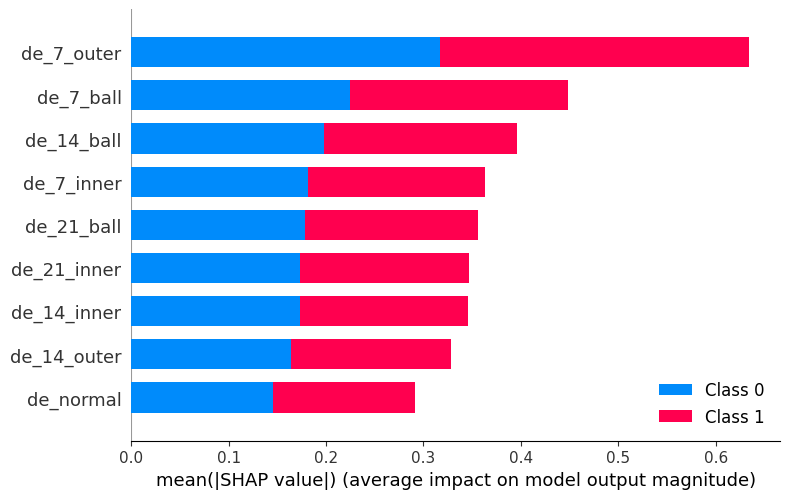

In [2]:
import pandas as pd
import shap
import lightgbm as lgb
from sklearn.model_selection import train_test_split

# 加载轴承振动监测数据集
file_path = 'data_12k_1797_10c.csv'
data = pd.read_csv(file_path)

# 截取时序信号前 10000 个采样点用于特征工程与分析
data = data.head(10000)

X = data.drop(data.columns[-1], axis=1)  # 末列作为目标状态标签分离特征矩阵
y = data[data.columns[-1]]

# 对连续型目标变量进行离散化
# 对连续型振动监测指标执行二值离散化标注
y = pd.cut(y, bins=2, labels=[0, 1])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 使用新的参数重新训练一个新的 LightGBM 模型
new_params = {'learning_rate': 0.05, 'n_estimators': 300, 'num_leaves': 40}
lgb_new = lgb.LGBMClassifier(**new_params)
lgb_new.fit(X_train, y_train)

# 使用 shap 进行解释
# 创建一个 SHAP 解释器，使用训练好的 LightGBM 模型
explainer = shap.Explainer(lgb_new)

# 计算 SHAP 值，使用训练集
shap_values = explainer.shap_values(X_train)

# 可视化所有类别的 SHAP 汇总图
shap.summary_plot(shap_values, X_train)